[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch10-concepts_workbook.ipynb)

# Five words, six bytes and two pairs

Of one text in English, Chinese and Bulgarian, the Chinese prints in the
fewest characters. Sent through GPT-2's tokenizer, which translation needs the
most tokens? The tokenizer starts from bytes and joins them by merges learned
from text. Which pair does BPE merge first in the lecture's five
words, how many bytes does `naïve` take, and which pair does WordPiece merge
where BPE merges another?

In [1]:
#@title Setup: run this cell first
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib import font_manager, ft2font

# The lecture's five-word corpus, each word with how often it occurs, and the end-of-word marker.
CORPUS = {"low": 5, "lower": 2, "new": 6, "newer": 3, "wider": 2}
END = "</w>"
# The lecture's ten Unigram log probabilities (natural logs), stylised.
LOGP = {"l": -3.0, "o": -2.8, "w": -3.2, "e": -2.5, "r": -2.9, "lo": -4.5, "ow": -5.0, "we": -6.0, "er": -4.0,
        "low": -5.5}
BYTE_VALUES = 256  # a byte is one of the values 0 to 255: the base tokens of byte-level BPE
# The characters the chart's font draws; a missing one would print a warning, so it shows as its code point.
GLYPHS = set(ft2font.FT2Font(font_manager.findfont(font_manager.FontProperties())).get_charmap())
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def drawable(s):  # s with each character the font lacks, and each control or combining one, as its code point
    s = "".join(c if c == " " or (ord(c) in GLYPHS and unicodedata.category(c)[0] in "LNPS") else f"U+{ord(c):04X}"
                for c in s)
    return s.replace("$", "\\$")  # two $ would start matplotlib's mathematics


def bars(title, labels, panels):  # one chart: a panel of labelled horizontal bars per (xlabel, values, texts, colours)
    fig, axes = plt.subplots(1, len(panels), figsize=(6.4, 0.4 * len(labels) + 1.4), layout="constrained",
                             sharey=True, squeeze=False)
    for ax, (xlabel, values, texts, colors) in zip(axes[0], panels):
        b = ax.barh(range(len(values)), values, tick_label=labels, color=colors)
        ax.bar_label(b, labels=texts, padding=2, fontsize=8)
        lo, hi = min(0, *values), max(0, *values)
        ax.set(xlabel=xlabel, xlim=(1.5 * lo, 1.5 * hi or 1), ylim=(len(values) - 0.5, -0.5))
        ax.xaxis.set_major_locator(plt.MaxNLocator(4, steps=[1, 2, 5, 10]))
    fig.suptitle(title, fontsize=10)
    plt.show()


# Step 1: BPE counts every adjacent pair over the corpus, each word weighted by how often it occurs.
def pair_counts(segs):
    count = Counter()
    for w, s in segs.items():
        for p in zip(s, s[1:]):
            count[p] += CORPUS[w]
    return count


def join(s, a, b):  # the symbols s with each adjacent a b, read left to right, joined into ab
    out, i = [], 0
    while i < len(s):
        k = 2 if s[i:i + 2] == [a, b] else 1
        out, i = out + ["".join(s[i:i + k])], i + k
    return out


# BPE until each word is one symbol. A tie goes to the pair seen first; the lecture's frame gives the same
# counts under that rule and under the alphabetically last. Per merge: the pair, its count, how many
# pairs had that count, and the symbols left in the corpus.
def learn():
    segs, rows = {w: [*w, END] for w in CORPUS}, []
    while count := pair_counts(segs):
        (a, b), c = count.most_common(1)[0]
        segs = {w: join(s, a, b) for w, s in segs.items()}
        rows.append((a, b, c, list(count.values()).count(c), sum(len(s) * CORPUS[w] for w, s in segs.items())))
    return rows


MERGE_LOG = learn()
WORDS, SYMBOLS = sum(CORPUS.values()), sum((len(w) + 1) * n for w, n in CORPUS.items())
BASE = list(dict.fromkeys(x for w in CORPUS for x in [*w, END]))


def merges(k):
    if type(k) is not int or not 0 <= k <= len(MERGE_LOG):
        raise Refused(f"MERGES is {k!r}: MERGES takes a whole number from 0 to {len(MERGE_LOG)}, "
                      f"and after {len(MERGE_LOG)} merges each word is one symbol.")
    return MERGE_LOG[:k]


def show_bpe(k):
    rows = merges(k)
    print(f"{WORDS} words in {SYMBOLS} symbols, {SYMBOLS / WORDS:.2f} per word, over {len(BASE)} base symbols")
    for i, (a, b, c, tied, n) in enumerate(rows, 1):
        print(f"merge {i}: {a} + {b} at {c}" + (f" (tie of {tied})" if tied > 1 else "") + f", {n} symbols, "
              f"{n / WORDS:.2f} per word")
    after = f"{k} merge" + ("" if k == 1 else "s")
    print(f"vocabulary: {len(BASE)} base symbols and {after}, {len(BASE) + k} entries")
    per = [SYMBOLS / WORDS] + [n / WORDS for *_, n in rows]
    bars(f"symbols per word after {after}", ["letters and " + END] + [f"{i}. {a} + {b} at {c}" for i, (a, b, c, _, _)
         in enumerate(rows, 1)], [("symbols per word", per, [f"{x:.2f}" for x in per], ["C7"] + ["C0"] * k)])


# Step 2: each character of a string and its UTF-8 bytes.
def utf8(text):
    # A lone surrogate, half of a UTF-16 pair, is no character, and UTF-8 has no bytes for it.
    if not (isinstance(text, str) and 1 <= len(text) <= 20 and not any(0xD800 <= ord(c) <= 0xDFFF for c in text)):
        raise Refused(f"TEXT is {text!r}: TEXT takes a string of 1 to 20 characters that UTF-8 can write.")
    return [(c, list(c.encode("utf-8"))) for c in text]


def show_bytes(text):
    chars = utf8(text)
    n = sum(len(b) for _, b in chars)
    print(" | ".join(f"{c!r} {' '.join(map(str, b))}" for c, b in chars))
    print(f"{len(chars)} character{'s' * (len(chars) > 1)}, {n} byte{'s' * (n > 1)}; by word: "
          + ", ".join(f"{w} {len(w.encode('utf-8'))}" for w in text.split()))
    bars(f"UTF-8 bytes of each character, {n} in all", [drawable(repr(c)) for c, _ in chars],
         [("bytes", [len(b) for _, b in chars], [" ".join(map(str, b)) for _, b in chars],
           [["C7", "C0", "C3", "C1"][len(b) - 1] for _, b in chars])])


# Step 3: BPE merges the pair with the highest count; WordPiece the one with the highest
# count(ab) / (count(a) × count(b)). Each pair comes with its count and the counts of its two symbols.
def scores(pairs):
    if not (isinstance(pairs, dict) and 1 <= len(pairs) <= 6 and all(
            isinstance(p, str) and p.isprintable() and len(p.split()) == 2 and isinstance(v, (tuple, list))
            and len(v) == 3 and all(type(x) is int for x in v) and 1 <= v[0] <= min(v[1:]) and max(v) <= 10 ** 9
            for p, v in pairs.items())):
        raise Refused(f"PAIRS is {pairs!r}: PAIRS takes 1 to 6 pairs written 'a b', each with three whole numbers up "
                      "to 1,000,000,000: its count, at least 1, and the counts of a and of b, each at least the pair's.")
    return {p: (j, j / (a * b)) for p, (j, a, b) in pairs.items()}


def show_pairs(pairs):
    s = scores(pairs)
    for p, (j, a, b) in pairs.items():
        print(f"{p}: count {j}, score {j} / ({a} × {b}) = {s[p][1]:.2g}")
    by_count, by_score = max(s, key=lambda p: s[p][0]), max(s, key=lambda p: s[p][1])
    print(f"BPE merges {by_count}; WordPiece merges {by_score}")
    bars("BPE merges the highest count, WordPiece the highest count(ab) / (count(a) × count(b))",
         [drawable(p) for p in s],
         [("BPE: count of the pair", [j for j, _ in s.values()], [f"{j:,}" for j, _ in s.values()],
           ["C3" if p == by_count else "C0" for p in s]),
          ("WordPiece: score", [x for _, x in s.values()], [f"{x:.2g}" for _, x in s.values()],
           ["C3" if p == by_score else "C0" for p in s])])


# Appendix: Viterbi keeps, for each prefix of the word, its best score b(i), the largest b(j) plus the log
# probability of the piece from j to i, and the pieces that give it. A tie goes to the longer last piece.
def viterbi(word, logp):
    best = [(0.0, [])]
    for i in range(1, len(word) + 1):
        best.append(max(((best[j][0] + logp[word[j:i]], best[j][1] + [word[j:i]]) for j in range(i)
                         if word[j:i] in logp), key=lambda x: x[0]))
    return best[1:]


def show_viterbi(logp):
    best = viterbi("lower", logp)
    bars("Viterbi's best score of each prefix of lower", [f"b({i}) {'lower'[:i]}: {' + '.join(s)}" for i, (_, s)
         in enumerate(best, 1)], [("sum of log probabilities", [v for v, _ in best], [f"{v + 0.0:.1f}" for v, _ in best],
                                   ["C0"] * (len(best) - 1) + ["C3"])])


display(Markdown(f"Corpus: {', '.join(f'`{w}` {n}' for w, n in CORPUS.items())}; {WORDS} words in {SYMBOLS} symbols, "
                 f"{len(BASE)} base symbols with `{END}`. Log probabilities of {len(LOGP)} pieces for `lower`."))

Corpus: `low` 5, `lower` 2, `new` 6, `newer` 3, `wider` 2; 18 words in 86 symbols, 9 base symbols with `</w>`. Log probabilities of 10 pieces for `lower`.

## 1. BPE on five words

BPE spells each word in letters and the end-of-word marker `</w>`, counts
every adjacent pair over the corpus and joins the most frequent pair into one
new symbol. The lecture's corpus holds `low` 5 times, `lower` 2, `new` 6,
`newer` 3 and `wider` 2. Each merge removes as many symbols as the pair's
count. Run the cell for the first merge. Then set `MERGES` to 10: how many
symbols per word are left?

18 words in 86 symbols, 4.78 per word, over 9 base symbols
merge 1: w + </w> at 11, 75 symbols, 4.17 per word
vocabulary: 9 base symbols and 1 merge, 10 entries


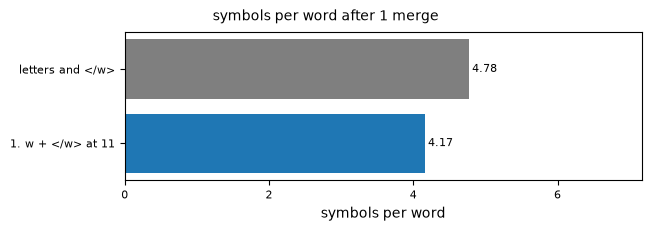

In [2]:
MERGES = 1
show_bpe(MERGES)

### Solution

In [3]:
first, ten = merges(1)[0], merges(10)
display(Markdown(f"The first merge joins `{first[0]}` and `{first[1]}` at {first[2]}: `low` ends in `w` {CORPUS['low']} "
                 f"times and `new` {CORPUS['new']} times. Ten merges at counts {', '.join(str(r[2]) for r in ten[:-1])} and {ten[-1][2]} take the "
                 f"{WORDS} words from {SYMBOLS} symbols, {SYMBOLS / WORDS:.2f} per word, to {ten[-1][4]}, "
                 f"{ten[-1][4] / WORDS:.2f} per word; merge 3 is a tie of {ten[2][3]} pairs at {ten[2][2]}, and any of "
                 f"them leaves {ten[2][4]} symbols."))

The first merge joins `w` and `</w>` at 11: `low` ends in `w` 5 times and `new` 6 times. Ten merges at counts 11, 9, 7, 7, 7, 6, 5, 5, 3 and 2 take the 18 words from 86 symbols, 4.78 per word, to 24, 1.33 per word; merge 3 is a tie of 3 pairs at 7, and any of them leaves 59 symbols.

## 2. UTF-8 bytes

UTF-8 writes an ASCII character in 1 byte, a Cyrillic letter in 2 and a
Chinese character in 3. A byte takes one of 256 values, and a BPE whose base
tokens are those 256 values encodes every string. `TEXT` holds
`naïve`, with the diaeresis on the `i`. Run the cell. Then set `TEXT` to
`cat 猫 котка`, the word for cat in English, Chinese and Bulgarian: how many
bytes does `котка` take?

'n' 110 | 'a' 97 | 'ï' 195 175 | 'v' 118 | 'e' 101
5 characters, 6 bytes; by word: naïve 6


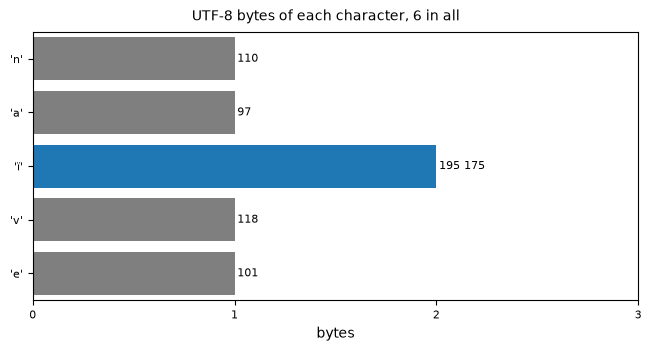

In [4]:
TEXT = "naïve"
show_bytes(TEXT)

### Solution

In [5]:
a, w = utf8("na\u00efve"), {x: len(x.encode("utf-8")) for x in "cat 猫 котка".split()}
display(Markdown(f"`na\u00efve` takes {sum(len(b) for _, b in a)} bytes for {len(a)} characters, because `\u00ef` takes "
                 f"{len(a[2][1])} bytes, {a[2][1][0]} and {a[2][1][1]}. `cat` takes {w['cat']} bytes, `猫` {w['猫']} and "
                 f"`котка` {w['котка']}, so a byte-level BPE starts `котка` from {w['котка']} base tokens, each one "
                 f"of the {BYTE_VALUES} byte values. GPT-2 learned few merges of Cyrillic bytes and gives the lecture's "
                 f"Bulgarian text {5.51} times the English tokens, the Chinese {3.21}: the Bulgarian needs the most."))

`naïve` takes 6 bytes for 5 characters, because `ï` takes 2 bytes, 195 and 175. `cat` takes 3 bytes, `猫` 3 and `котка` 10, so a byte-level BPE starts `котка` from 10 base tokens, each one of the 256 byte values. GPT-2 learned few merges of Cyrillic bytes and gives the lecture's Bulgarian text 5.51 times the English tokens, the Chinese 3.21: the Bulgarian needs the most.

## 3. BPE's count against WordPiece's score

BPE merges the most frequent pair. WordPiece divides how often a pair occurs
by how often each of its two symbols occurs, and merges the pair with the
highest ratio. `PAIRS` holds the two pairs of the lecture's checkpoint: `q u`
occurs 40 times, `q` 40 and `u` 200; `t h` occurs 300 times, `t` 900 and `h`
400. Run the cell. Then
set `PAIRS` to `{"w </w>": (11, 18, 18), "i d": (2, 2, 2)}`, two pairs of the
five-word corpus: which of them does WordPiece merge?

q u: count 40, score 40 / (40 × 200) = 0.005
t h: count 300, score 300 / (900 × 400) = 0.00083
BPE merges t h; WordPiece merges q u


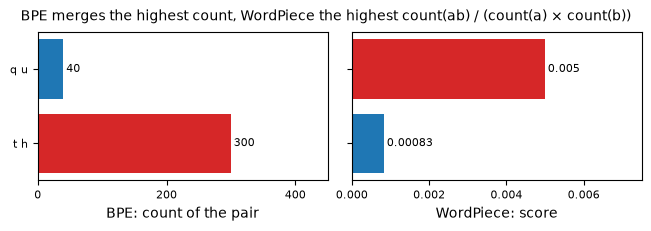

In [6]:
PAIRS = {"q u": (40, 40, 200), "t h": (300, 900, 400)}
show_pairs(PAIRS)

### Solution

In [7]:
c, f = scores({"q u": (40, 40, 200), "t h": (300, 900, 400)}), scores({"w </w>": (11, 18, 18), "i d": (2, 2, 2)})
display(Markdown(f"BPE merges `t h`, at {c['t h'][0]} against {c['q u'][0]}, and WordPiece merges `q u`, {c['q u'][1]:.2g} "
                 f"against {c['t h'][1]:.2g}, because `q` never occurs apart from `u`. In the five-word corpus BPE merges "
                 f"`w </w>` at {f['w </w>'][0]} and WordPiece merges `i d`, {f['i d'][1]:.2g} against "
                 f"{f['w </w>'][1]:.2g}, because `i` and `d` occur only inside `wider`."))

BPE merges `t h`, at 300 against 40, and WordPiece merges `q u`, 0.005 against 0.00083, because `q` never occurs apart from `u`. In the five-word corpus BPE merges `w </w>` at 11 and WordPiece merges `i d`, 0.5 against 0.034, because `i` and `d` occur only inside `wider`.

## Appendix. Viterbi segmentation of `lower`

A Unigram tokenizer gives each piece a log probability and scores a
segmentation by the sum over its pieces. Viterbi keeps the best score b(i)
of the first i characters of a word, the largest b(j) plus the log
probability of the piece from j to i. The lecture's ten pieces are `l` -3.0,
`o` -2.8, `w` -3.2, `e` -2.5, `r` -2.9, `lo` -4.5, `ow` -5.0, `we` -6.0,
`er` -4.0 and `low` -5.5. For `lower`, Viterbi finds the best of the 10
segmentations without listing them.

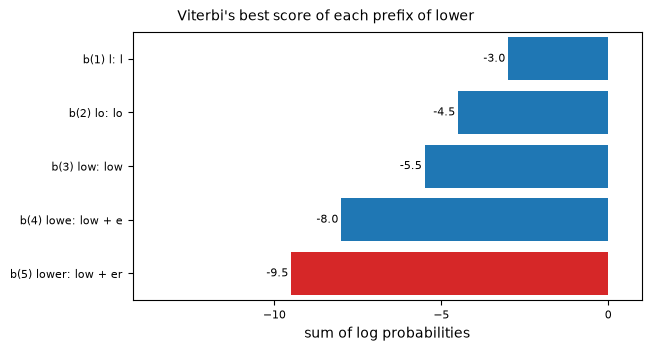

In [8]:
show_viterbi(LOGP)

**Exercise.** Set `LOG_P` to -5.5, a lower log probability for `er`, and
rerun the cell. Which segmentation of `lower` does Viterbi pick now, and at
what score?

In [9]:
PIECE = "er"
LOG_P = -4.0

if not (isinstance(PIECE, str) and PIECE in LOGP):
    raise Refused(f"PIECE is {PIECE!r}: PIECE takes one of the ten pieces {', '.join(LOGP)}.")
if type(LOG_P) not in (int, float) or not -20 <= LOG_P <= 0:
    raise Refused(f"LOG_P is {LOG_P!r}: LOG_P takes a log probability, a number from -20 to 0.")
best = viterbi("lower", {**LOGP, PIECE: LOG_P})
print("; ".join(f"b({i}) {v + 0.0:.1f}, {' + '.join(s)}" for i, (v, s) in enumerate(best, 1)))

b(1) -3.0, l; b(2) -4.5, lo; b(3) -5.5, low; b(4) -8.0, low + e; b(5) -9.5, low + er


### Solution

In [10]:
old, new = viterbi("lower", LOGP)[-1], viterbi("lower", {**LOGP, "er": -5.5})[-1]
display(Markdown(f"With `er` at -4.0 Viterbi picks `{' + '.join(old[1])}` at {old[0]:.1f}. With `er` at -5.5, "
                 f"`low + er` scores {LOGP['low'] - 5.5:.1f} and Viterbi picks `{' + '.join(new[1])}` at {new[0]:.1f}: "
                 f"the piece `er` wins while its log probability stays above {LOGP['e'] + LOGP['r']:.1f}, the sum of "
                 "the log probabilities of `e` and `r`."))

With `er` at -4.0 Viterbi picks `low + er` at -9.5. With `er` at -5.5, `low + er` scores -11.0 and Viterbi picks `low + e + r` at -10.9: the piece `er` wins while its log probability stays above -5.4, the sum of the log probabilities of `e` and `r`.